# 09 · Subgraphs: Composing Graphs  🟠 Advanced

Big systems are built from smaller graphs. A compiled graph can be used **as a node** in another graph.

Two ways to connect them:
| Situation | How |
|---|---|
| Parent and child **share state keys** | `parent.add_node("child", child_graph)` directly |
| **Different schemas** | call `child_graph.invoke(...)` inside a node and map inputs/outputs |

Subgraphs give you: reuse, team ownership, private state, and separate testing.

In [1]:
from helpers import get_llm, show_graph, print_messages

llm = get_llm()   # ChatAnthropic -> Claude, key read from CLAUDE_KEY in .env

## 1. Subgraph with shared keys

Child state: `question`, `notes` (shared with parent) + `queries` (private to the child).

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

FAKE_SEARCH = {
    "definition": "LangGraph is a low-level orchestration framework for stateful, long-running agents.",
    "features": "Key features: durable execution, human-in-the-loop, memory, streaming, subgraphs.",
    "companies": "Used in production by companies such as Klarna, Uber, Replit and Elastic.",
}

class ResearchState(TypedDict):
    question: str       # shared with parent
    queries: list[str]  # private
    notes: str          # shared with parent

def make_queries(state: ResearchState):
    return {"queries": list(FAKE_SEARCH)}            # pretend we generated search queries

def run_search(state: ResearchState):
    notes = "\n".join(f"- {FAKE_SEARCH[q]}" for q in state["queries"])
    return {"notes": notes}

rb = StateGraph(ResearchState)
rb.add_node(make_queries); rb.add_node(run_search)
rb.add_edge(START, "make_queries"); rb.add_edge("make_queries", "run_search"); rb.add_edge("run_search", END)
research_graph = rb.compile()

research_graph.invoke({"question": "What is LangGraph?"})      # a subgraph is a normal graph: test it alone

{'question': 'What is LangGraph?',
 'queries': ['definition', 'features', 'companies'],
 'notes': '- LangGraph is a low-level orchestration framework for stateful, long-running agents.\n- Key features: durable execution, human-in-the-loop, memory, streaming, subgraphs.\n- Used in production by companies such as Klarna, Uber, Replit and Elastic.'}

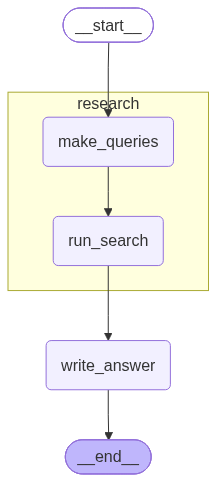

In [3]:
class ParentState(TypedDict):
    question: str
    notes: str
    answer: str
    translated: str

def write_answer(state: ParentState):
    prompt = f"Using only these notes, answer in 2 sentences.\nNotes:\n{state['notes']}\n\nQuestion: {state['question']}"
    return {"answer": llm.invoke(prompt).text}

pb = StateGraph(ParentState)
pb.add_node("research", research_graph)      # 👈 compiled graph used as a node
pb.add_node(write_answer)
pb.add_edge(START, "research"); pb.add_edge("research", "write_answer"); pb.add_edge("write_answer", END)
parent = pb.compile()
show_graph(parent, xray=True)                # xray=True draws the inside of subgraphs

In [4]:
out = parent.invoke({"question": "What is LangGraph and who uses it?"})
print(out["answer"])
print("\nPrivate 'queries' leaked to parent?", "queries" in out)

LangGraph is a low-level orchestration framework for building stateful, long-running agents, offering key features such as durable execution, human-in-the-loop, memory, streaming, and subgraphs. It is used in production by companies including Klarna, Uber, Replit, and Elastic.

Private 'queries' leaked to parent? False


## 2. Subgraph with a different schema

The translation team built a graph with keys `text`, `language`, `translated`.
We call it inside a node and **map** parent ↔ child state.

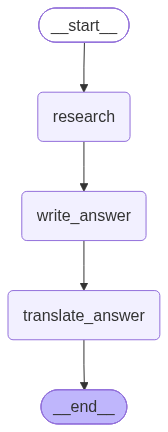

In [5]:
class TranslateState(TypedDict):
    text: str
    language: str
    translated: str

def translate(state: TranslateState):
    out = llm.invoke(f"Translate to {state['language']}. Output only the translation:\n{state['text']}").text
    return {"translated": out}

tb = StateGraph(TranslateState)
tb.add_node(translate); tb.add_edge(START, "translate"); tb.add_edge("translate", END)
translate_graph = tb.compile()

def translate_answer(state: ParentState):
    child_out = translate_graph.invoke({"text": state["answer"], "language": "Hindi"})   # map in
    return {"translated": child_out["translated"]}                                      # map out

pb = StateGraph(ParentState)
pb.add_node("research", research_graph)
pb.add_node(write_answer); pb.add_node(translate_answer)
pb.add_edge(START, "research"); pb.add_edge("research", "write_answer")
pb.add_edge("write_answer", "translate_answer"); pb.add_edge("translate_answer", END)
full = pb.compile()
show_graph(full)

## 3. Streaming from inside subgraphs

`subgraphs=True` yields `(namespace, update)`. The namespace tells you *where* the event came from
(`()` = parent, `('research:<id>',)` = inside the subgraph).

In [6]:
for namespace, update in full.stream({"question": "What is LangGraph?"}, stream_mode="updates", subgraphs=True):
    where = "parent" if not namespace else " > ".join(ns.split(":")[0] for ns in namespace)
    for node, changes in update.items():
        print(f"[{where:>18}] {node:<16} -> {list(changes or {})}")

[          research] make_queries     -> ['queries']
[          research] run_search       -> ['notes']
[            parent] research         -> ['question', 'notes']


[            parent] write_answer     -> ['answer']


[  translate_answer] translate        -> ['translated']
[            parent] translate_answer -> ['translated']


## 4. Persistence with subgraphs

Give the checkpointer **only to the parent**; subgraphs inherit it automatically.
Interrupts inside a subgraph pause the whole parent run and resume correctly.

In [7]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

def review_notes(state: ResearchState):
    ok = interrupt({"notes": state["notes"], "question": "Are these notes OK?"})
    return {} if ok else {"notes": "- (notes rejected by reviewer)"}

rb2 = StateGraph(ResearchState)
rb2.add_node(make_queries); rb2.add_node(run_search); rb2.add_node(review_notes)
rb2.add_edge(START, "make_queries"); rb2.add_edge("make_queries", "run_search")
rb2.add_edge("run_search", "review_notes"); rb2.add_edge("review_notes", END)

pb = StateGraph(ParentState)
pb.add_node("research", rb2.compile())               # no checkpointer here...
pb.add_node(write_answer)
pb.add_edge(START, "research"); pb.add_edge("research", "write_answer"); pb.add_edge("write_answer", END)
reviewed = pb.compile(checkpointer=InMemorySaver())  # ...only on the parent

config = {"configurable": {"thread_id": "sub-1"}}
res = reviewed.invoke({"question": "What is LangGraph?"}, config)
print("⏸️ paused inside subgraph:", res["__interrupt__"][0].value["question"])
state = reviewed.get_state(config, subgraphs=True)
print("subgraph is waiting at:", state.tasks[0].state.next)
print("\n▶️", reviewed.invoke(Command(resume=True), config)["answer"])

⏸️ paused inside subgraph: Are these notes OK?
subgraph is waiting at: ('review_notes',)



▶️ LangGraph is a low-level orchestration framework for building stateful, long-running agents, with key features including durable execution, human-in-the-loop, memory, streaming, and subgraphs. It is used in production by companies such as Klarna, Uber, Replit, and Elastic.


## ✅ Recap
* Shared keys → add the compiled subgraph directly as a node; private keys stay private.
* Different schemas → invoke the subgraph inside a node and map state in/out.
* `show_graph(g, xray=True)` and `stream(..., subgraphs=True)` reveal the internals.
* Checkpointer on the parent only; interrupts in subgraphs just work.